<a href="https://colab.research.google.com/github/Asif-Ahmed-Rezvi/flyrank-internship-ml/blob/main/work/notebooks/w04_signal_audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML-06 — Signal Audit: Do the Flags Hold?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Asif-Ahmed-Rezvi/flyrank-internship-ml/blob/main/work/notebooks/w04_signal_audit.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Distributions


### Distribution audit

I use the anonymized starter dataset containing 30,000 content items across 32 pseudonymized clients. Before testing individual signals, I inspect the distributions of search impressions, clicks, click-through rate (CTR), average search position, content age, and days since the last update.

Traffic counts are likely to be right-skewed, so I report medians and upper percentiles alongside the means and use `log1p` histograms to make the long tails easier to inspect.

Two measurement details matter: CTR is expressed as a percentage multiplied by 100 (for example, `0.76` means 0.76%), and `avg_position = 0` means no position data rather than a real ranking. I exclude zero-position rows from the position distribution, but report their count separately.


Repository: /content/flyrank-internship-ml
Dataset shape: 30,000 rows × 44 columns
Distinct clients: 32
Distinct content items: 30,000

Distribution summary:


,count,mean,std,min,50%,75%,90%,95%,99%,max,missing_n,zero_n,missing_pct
impressions_90d,30000.0,5200.366,16838.020,1.0,731.00,3615.25,12136.40,22996.50,73505.830,517715.0,0,0,0.0
clicks_90d,30000.0,16.097,75.077,0.0,1.00,7.00,32.00,69.05,253.010,4178.0,0,13204,0.0
ctr,30000.0,0.511,3.279,0.0,0.07,0.29,0.65,1.09,8.330,100.0,0,13212,0.0
avg_position,30000.0,16.342,15.217,0.0,10.80,22.30,36.80,48.20,69.901,245.0,0,1205,0.0
content_age_days,30000.0,256.168,132.708,90.0,236.00,333.00,463.00,487.00,537.000,564.0,0,0,0.0
days_since_last_update,30000.0,46.098,42.079,1.0,20.00,104.00,104.00,104.00,106.000,373.0,0,0,0.0



Rows with avg_position = 0: 1,205
Rows with a positive average position: 28,795
CTR scale reminder: 0.76 represents 0.76%, not 76%.


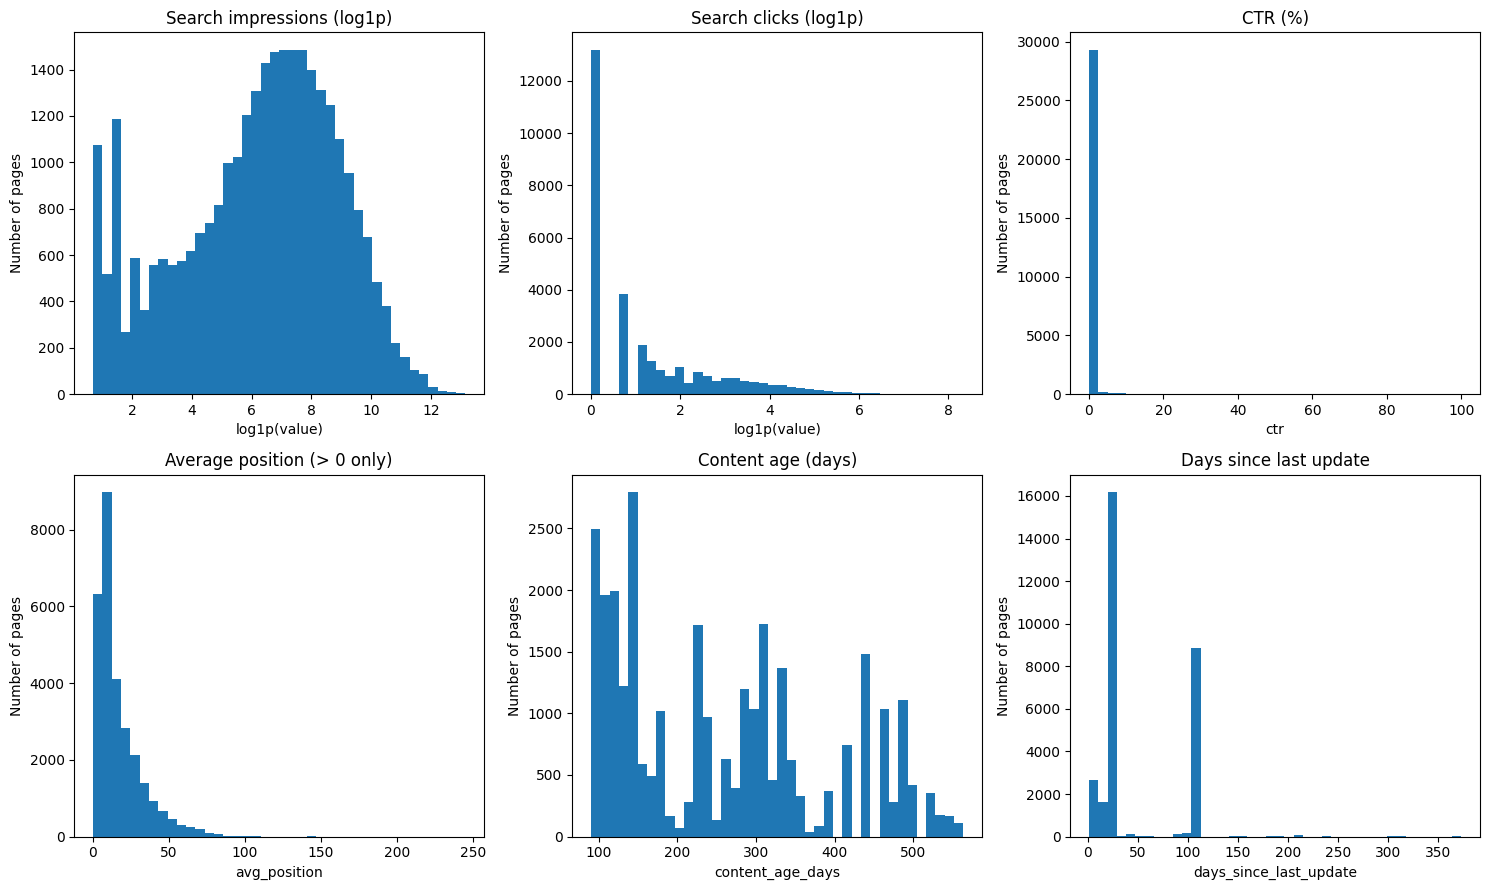


Missing-value audit:


,missing_n,missing_pct
impressions_90d,0,0.0
clicks_90d,0,0.0
ctr,0,0.0
avg_position,0,0.0
content_age_days,0,0.0
days_since_last_update,0,0.0


In [1]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the repository and load the real starter dataset.
REPO_DIR = Path("/content/flyrank-internship-ml")

if os.environ.get("COLAB_RELEASE_TAG"):
    if not REPO_DIR.exists():
        !git clone -q https://github.com/Asif-Ahmed-Rezvi/flyrank-internship-ml {REPO_DIR}
    ROOT = REPO_DIR
else:
    candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    ROOT = next(
        (
            p for p in candidates
            if (p / "data/raw/content_refresh_anonymized.csv").exists()
        ),
        None,
    )
    if ROOT is None:
        raise FileNotFoundError(
            "Repository not found. Open this notebook from the "
            "FlyRank repository or use the provided Colab link."
        )

DATA_PATH = ROOT / "data/raw/content_refresh_anonymized.csv"
df = pd.read_csv(DATA_PATH)

print(f"Repository: {ROOT}")
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]:,} columns")
print(f"Distinct clients: {df['client_id'].nunique():,}")
print(f"Distinct content items: {df['content_id'].nunique():,}")

# Inspect the fields relevant to the signal audit.
numeric_fields = [
    "impressions_90d",
    "clicks_90d",
    "ctr",
    "avg_position",
    "content_age_days",
    "days_since_last_update",
]

missing_fields = [c for c in numeric_fields if c not in df.columns]
if missing_fields:
    raise KeyError(f"Expected columns are missing: {missing_fields}")

for col in numeric_fields:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Summarize central tendency, spread, and heavy tails.
distribution = df[numeric_fields].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
).T

distribution["missing_n"] = df[numeric_fields].isna().sum()
distribution["zero_n"] = (df[numeric_fields] == 0).sum()
distribution["missing_pct"] = (
    100 * distribution["missing_n"] / len(df)
).round(2)

print("\nDistribution summary:")
display(distribution.round(3))

# Position zero means "no position data", so separate it from real positions.
no_position = df["avg_position"].eq(0)
valid_position = df.loc[
    df["avg_position"].gt(0), "avg_position"
].dropna()

print(f"\nRows with avg_position = 0: {no_position.sum():,}")
print(f"Rows with a positive average position: {len(valid_position):,}")
print(
    "CTR scale reminder: 0.76 represents 0.76%, "
    "not 76%."
)

# Plot distributions. Traffic counts use log1p to expose their long tails.
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

plot_specs = [
    ("impressions_90d", "Search impressions (log1p)", True),
    ("clicks_90d", "Search clicks (log1p)", True),
    ("ctr", "CTR (%)", False),
    ("avg_position", "Average position (> 0 only)", False),
    ("content_age_days", "Content age (days)", False),
    ("days_since_last_update", "Days since last update", False),
]

for ax, (col, title, use_log) in zip(axes.flat, plot_specs):
    values = df[col].dropna()

    if col == "avg_position":
        values = values[values > 0]

    if use_log:
        values = np.log1p(values.clip(lower=0))
        ax.set_xlabel("log1p(value)")
    else:
        ax.set_xlabel(col)

    ax.hist(values, bins=40)
    ax.set_title(title)
    ax.set_ylabel("Number of pages")

plt.tight_layout()
plt.show()

# Inspect missingness in the fields used by this audit.
missing_summary = pd.DataFrame({
    "missing_n": df[numeric_fields].isna().sum(),
    "missing_pct": (
        100 * df[numeric_fields].isna().mean()
    ).round(2),
})

print("\nMissing-value audit:")
display(missing_summary)


## 2. Signal test #1 / #2 / #3 (verdict each)


## Signal test #1 — Does search visibility translate into clicks?

**Claim:** Pages with more search impressions tend to receive more clicks.

**Test:** Compare median impressions and clicks across traffic-volume bands. Report the number of pages in each band because the distribution is heavily right-skewed.

**Interpretation:** If median clicks increase with traffic volume, impressions are useful for prioritizing pages with meaningful search exposure. This does not establish that increasing impressions alone will improve performance.

## Signal test #2 — Is search position associated with CTR?

**Claim:** Pages ranking lower in search results tend to have lower CTR.

**Test:** Among pages with at least 500 impressions and a positive average position, compare median CTR and the share with CTR below 0.5% across position bands.

**Interpretation:** A lower CTR among positions 11–20 may support prioritizing visible pages for review. CTR also depends on query intent, SERP features, and other factors.

## Signal test #3 — Is update recency associated with CTR?

**Claim:** Pages that have gone longer without an update tend to have weaker CTR.

**Test:** Among pages with at least 500 impressions and a positive average position, compare median CTR and low-CTR share across update-recency bands.

In [2]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

# Signal tests: traffic volume, search position, and update recency.

from scipy.stats import spearmanr

audit_df = df.copy()

# Ensure the fields used in the tests are numeric.
for col in [
    "impressions_90d",
    "clicks_90d",
    "ctr",
    "avg_position",
    "days_since_last_update",
]:
    audit_df[col] = pd.to_numeric(audit_df[col], errors="coerce")

# ---------------------------------------------------------
# Test 1: Traffic volume and clicks
# ---------------------------------------------------------
audit_df["traffic_band"] = pd.cut(
    audit_df["impressions_90d"],
    bins=[0, 100, 500, 3000, np.inf],
    labels=["1–100", "101–500", "501–3000", "3000+"],
    include_lowest=True,
)

traffic_test = (
    audit_df.groupby("traffic_band", observed=False)
    .agg(
        n=("content_id", "size"),
        median_impressions=("impressions_90d", "median"),
        median_clicks=("clicks_90d", "median"),
        mean_clicks=("clicks_90d", "mean"),
    )
    .reset_index()
)

print("TEST 1 — Traffic volume and clicks")
display(traffic_test.round(3))

traffic_valid = audit_df[
    ["impressions_90d", "clicks_90d"]
].dropna()

traffic_rho, traffic_p = spearmanr(
    traffic_valid["impressions_90d"],
    traffic_valid["clicks_90d"],
)

print(
    f"Spearman correlation between impressions and clicks: "
    f"rho={traffic_rho:.3f}, p={traffic_p:.3g}, "
    f"n={len(traffic_valid):,}"
)

# ---------------------------------------------------------
# Shared eligible population for Tests 2 and 3
# ---------------------------------------------------------
eligible = audit_df[
    (audit_df["impressions_90d"] >= 500)
    & (audit_df["avg_position"] > 0)
].copy()

eligible["low_ctr"] = eligible["ctr"] < 0.5

# ---------------------------------------------------------
# Test 2: Search position and CTR
# ---------------------------------------------------------
eligible["position_band"] = pd.cut(
    eligible["avg_position"],
    bins=[0, 3, 10, 20, np.inf],
    labels=["1–3", "4–10", "11–20", "21+"],
    include_lowest=False,
)

position_test = (
    eligible.groupby("position_band", observed=False)
    .agg(
        n=("content_id", "size"),
        median_position=("avg_position", "median"),
        median_ctr=("ctr", "median"),
        low_ctr_n=("low_ctr", "sum"),
        low_ctr_share=("low_ctr", "mean"),
        median_impressions=("impressions_90d", "median"),
    )
    .reset_index()
)

position_test["low_ctr_share_pct"] = (
    100 * position_test["low_ctr_share"]
)

print("\nTEST 2 — Search position and CTR")
display(
    position_test[
        [
            "position_band",
            "n",
            "median_position",
            "median_ctr",
            "low_ctr_n",
            "low_ctr_share_pct",
            "median_impressions",
        ]
    ].round(3)
)

position_valid = eligible[
    ["avg_position", "ctr"]
].dropna()

position_rho, position_p = spearmanr(
    position_valid["avg_position"],
    position_valid["ctr"],
)

print(
    f"Spearman correlation between position and CTR: "
    f"rho={position_rho:.3f}, p={position_p:.3g}, "
    f"n={len(position_valid):,}"
)

# ---------------------------------------------------------
# Test 3: Time since last update and CTR
# ---------------------------------------------------------
eligible["update_band"] = pd.cut(
    eligible["days_since_last_update"],
    bins=[0, 30, 60, 90, np.inf],
    labels=["1–30 days", "31–60 days", "61–90 days", "91+ days"],
    include_lowest=True,
)

update_test = (
    eligible.groupby("update_band", observed=False)
    .agg(
        n=("content_id", "size"),
        median_days_since_update=("days_since_last_update", "median"),
        median_ctr=("ctr", "median"),
        low_ctr_n=("low_ctr", "sum"),
        low_ctr_share=("low_ctr", "mean"),
    )
    .reset_index()
)

update_test["low_ctr_share_pct"] = (
    100 * update_test["low_ctr_share"]
)

print("\nTEST 3 — Update recency and CTR")
display(
    update_test[
        [
            "update_band",
            "n",
            "median_days_since_update",
            "median_ctr",
            "low_ctr_n",
            "low_ctr_share_pct",
        ]
    ].round(3)
)

update_valid = eligible[
    ["days_since_last_update", "ctr"]
].dropna()

update_rho, update_p = spearmanr(
    update_valid["days_since_last_update"],
    update_valid["ctr"],
)

print(
    f"Spearman correlation between days since update and CTR: "
    f"rho={update_rho:.3f}, p={update_p:.3g}, "
    f"n={len(update_valid):,}"
)

# Flag small groups so their results are not overinterpreted.
for test_name, table in [
    ("Traffic volume", traffic_test),
    ("Search position", position_test),
    ("Update recency", update_test),
]:
    small_groups = table.loc[table["n"] < 50]

    if not small_groups.empty:
        print(
            f"\nCaution — {test_name}: groups with fewer than "
            f"50 pages should not support strong conclusions:"
        )
        display(small_groups[["n"]])


TEST 1 — Traffic volume and clicks


,traffic_band,n,median_impressions,median_clicks,mean_clicks
0,1–100,8006,12.0,0.0,0.147
1,101–500,5279,253.0,0.0,0.586
2,501–3000,8432,1231.0,2.0,3.208
3,3000+,8283,8426.0,20.0,54.521


Spearman correlation between impressions and clicks: rho=0.826, p=0, n=30,000

TEST 2 — Search position and CTR


,position_band,n,median_position,median_ctr,low_ctr_n,low_ctr_share_pct,median_impressions
0,1–3,480,2.4,0.20,360,75.000,4382.5
1,4–10,7084,6.5,0.24,5609,79.178,4502.0
2,11–20,4459,14.0,0.17,3790,84.997,2166.0
3,21+,4703,29.2,0.08,4486,95.386,2217.0


Spearman correlation between position and CTR: rho=-0.376, p=0, n=16,726

TEST 3 — Update recency and CTR


,update_band,n,median_days_since_update,median_ctr,low_ctr_n,low_ctr_share_pct
0,1–30 days,10063,20.0,0.18,8505,84.518
1,31–60 days,75,41.0,0.10,72,96.000
2,61–90 days,13,89.0,0.07,13,100.000
3,91+ days,6575,104.0,0.15,5655,86.008


Spearman correlation between days since update and CTR: rho=-0.059, p=2.05e-14, n=16,726

Caution — Update recency: groups with fewer than 50 pages should not support strong conclusions:


,n
2,13



### Verdicts

**Test 1 — Impressions and clicks: CONFIRMED.**  
The observed association is strong (Spearman ρ = 0.826, n = 30,000). Median clicks rise from 0 in the two lowest traffic bands to 20 in the highest band. Impression volume is useful for identifying pages with meaningful exposure, but high volume alone does not mean a page needs refreshing.

**Test 2 — Search position and CTR: CONFIRMED.**  
Position and CTR have a moderate negative association (Spearman ρ = -0.376, n = 16,726). Median CTR falls from 0.24% at positions 4–10 to 0.08% at positions 21+. Search position helps contextualize CTR, but this observational relationship does not prove that changing position causes a particular CTR improvement.

**Test 3 — Update recency and CTR: MIXED.**  
The association is very weak (Spearman ρ = -0.059, n = 16,726). CTR does not follow a consistent pattern across update-recency bands, and the 61–90-day group has only 13 pages. Update recency alone is not supported as a strong prioritization signal by this test.

*Statistical note:* Report the first two p-values as p < 0.001 rather than p = 0; the displayed zero is a numerical precision limitation. Statistical significance does not imply practical importance or causality.



## 3. The flag-linked test

**Flag assumption:** Pages assigned to higher `impression_tier` categories should generally have more observed clicks.

**Test:** Compared page counts, median impressions, median clicks, and the share of pages with at least one click across the existing impression tiers.

**Verdict: CONFIRMED.** The pattern is consistent across all four observed tiers. Median clicks increase from 0 in the low tier to 1 in moderate, 16 in good, and 116 in excellent. The share of pages with at least one click rises from 15.84% to 66.02%, 97.50%, and 99.91%, respectively.

**Practical interpretation:** The impression-tier flag aligns with observed click volume and can help distinguish pages with different levels of search exposure. However, impressions define the tier, and clicks cover the same trailing 90-day window. This test does not establish independent predictive power or show that refreshing a page will improve its performance.


In [3]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

# Section 3: Validate the existing impression_tier flag.
# This cell uses observed outcomes only; it does not use trend labels.

if "impression_tier" not in df.columns:
    raise KeyError(
        "The raw dataset does not contain 'impression_tier'. "
        "Check df.columns and the data dictionary before proceeding."
    )

flag_df = df[
    ["content_id", "impression_tier", "impressions_90d", "clicks_90d"]
].copy()

flag_df["impressions_90d"] = pd.to_numeric(
    flag_df["impressions_90d"], errors="coerce"
)
flag_df["clicks_90d"] = pd.to_numeric(
    flag_df["clicks_90d"], errors="coerce"
)

flag_df = flag_df.dropna(
    subset=["impression_tier", "impressions_90d", "clicks_90d"]
)

flag_df["has_clicks"] = flag_df["clicks_90d"] > 0

flag_test = (
    flag_df.groupby("impression_tier", observed=True)
    .agg(
        n=("content_id", "size"),
        median_impressions=("impressions_90d", "median"),
        median_clicks=("clicks_90d", "median"),
        pages_with_clicks=("has_clicks", "sum"),
        click_positive_share=("has_clicks", "mean"),
    )
    .reset_index()
)

flag_test["click_positive_share_pct"] = (
    100 * flag_test["click_positive_share"]
)

# Display in the intended tier order when those labels are present.
tier_order = [
    "no_data", "none", "low", "moderate", "good", "excellent"
]

flag_test["_tier_order"] = (
    flag_test["impression_tier"]
    .astype(str)
    .map({tier: i for i, tier in enumerate(tier_order)})
)

flag_test = (
    flag_test.sort_values(
        ["_tier_order", "impression_tier"],
        na_position="last"
    )
    .drop(columns="_tier_order")
    .reset_index(drop=True)
)

print("FLAG-LINKED TEST — Impression tiers and observed clicks")
display(
    flag_test[
        [
            "impression_tier",
            "n",
            "median_impressions",
            "median_clicks",
            "pages_with_clicks",
            "click_positive_share_pct",
        ]
    ].round(3)
)

small_groups = flag_test[flag_test["n"] < 50]

if not small_groups.empty:
    print(
        "\nCaution: interpret tiers with fewer than 50 pages carefully."
    )
    display(small_groups[["impression_tier", "n"]])


FLAG-LINKED TEST — Impression tiers and observed clicks


,impression_tier,n,median_impressions,median_clicks,pages_with_clicks,click_positive_share_pct
0,low,11248,31.0,0.0,1782,15.843
1,moderate,10469,998.0,1.0,6912,66.023
2,good,7205,7249.0,16.0,7025,97.502
3,excellent,1078,48675.0,116.0,1077,99.907



## 4. What this means in practice

The audit supports using impression volume and search position to prioritize pages for review: higher exposure creates more opportunity for clicks, while lower search positions are associated with lower CTR. The existing impression-tier flag aligns with observed click volume, but update recency alone shows only a weak relationship with CTR and should not be used as a decisive signal.

A content team should treat these signals as decision support, not automatic refresh instructions. Review the page's query intent, SERP context, and content quality before deciding what to change, and evaluate future performance separately before claiming that a refresh caused an improvement.


In [4]:
# This cell is for CODE (numbers, a query, a check).
# Write you
# Section 4: Practical summary and final sanity checks.

print("PRACTICAL TAKEAWAYS")
print("- Impression volume is useful for understanding search exposure.")
print("- Search position is associated with CTR in the observed data.")
print("- Update recency alone is a weak CTR signal in this audit.")
print("- Impression tiers align with clicks in the same 90-day window.")
print("- These relationships are descriptive, not causal.")

# Verify that the three signal-test results and flag-linked test exist.
required_objects = [
    "traffic_test",
    "position_test",
    "update_test",
    "flag_test",
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        f"Run the earlier sections first. Missing objects: {missing_objects}"
    )

print("\nFINAL SANITY CHECKS")
print(f"Dataset rows: {len(df):,}")
print(f"Unique content items: {df['content_id'].nunique():,}")
print(f"Unique clients: {df['client_id'].nunique():,}")

assert len(df) == 30_000, "Unexpected dataset row count."
assert df["content_id"].nunique() == len(df), (
    "Expected one row per unique content item."
)

print("\nAll final sanity checks passed.")


PRACTICAL TAKEAWAYS
- Impression volume is useful for understanding search exposure.
- Search position is associated with CTR in the observed data.
- Update recency alone is a weak CTR signal in this audit.
- Impression tiers align with clicks in the same 90-day window.
- These relationships are descriptive, not causal.

FINAL SANITY CHECKS
Dataset rows: 30,000
Unique content items: 30,000
Unique clients: 32

All final sanity checks passed.


## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.